# MTA elevator reliability
### Do fewer outages mean better availability?

I compared the same MTA-operated elevators in 2024 and 2025 to understand whether
fewer interruptions meant more time available. This notebook follows the preparation,
checks the results, and explains the five views used in the Tableau dashboard.

**Tools:** Python, pandas, NumPy, Matplotlib and Tableau.

[Open the Tableau dashboard](https://public.tableau.com/app/profile/jubyaid.uddin/viz/MTA_Elevator_Reliability_2nd_Draft/NYCElevatorReliability)

Run the cells from top to bottom using the project environment described in the README.
The source is the frozen 7 October 2026 snapshot. One row represents one piece of
equipment in one month, not one outage.


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter, MaxNLocator

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts/prepare_data.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "scripts/prepare_data.py").exists():
    raise FileNotFoundError("Open the notebook from the project folder.")
sys.path.insert(0, str(ROOT / "scripts"))

from prepare_data import prepare
from validate_data import verify

RAW = ROOT / "data/raw/mta_availability_2026-10-07.csv"
PREPARED = ROOT / "data/processed/mta_elevators_2024_2025_tableau.csv"
REFERENCE = ROOT / "data/reference/mta_elevators_2024_2025_tableau.csv"
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)

NAVY, ORANGE, GRAY = "#22394C", "#C66738", "#A7AEB4"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.labelcolor": NAVY, "text.color": NAVY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.axisbelow": True, "figure.facecolor": "white",
})

def save_chart(figure, filename):
    figure.savefig(ASSETS / filename, dpi=160, facecolor=figure.get_facecolor())


## 1. Check the source

The full file includes both elevators and escalators, multiple years and external
operators. I checked dates, duplicate equipment-month keys, hours and outage counts
before comparing performance.

All 2,553 missing 24-hour availability percentages correspond to zero included hours.
Those rates are undefined. Filling them with zero would imply a measured 0% availability.
The raw snapshot is preserved without filling missing values or removing outliers.


In [2]:
raw = pd.read_csv(RAW)
raw["Month"] = pd.to_datetime(raw["Month"], errors="raise")
available = raw["24-Hour Hours Available"]
included = raw["24-Hour Total Hours"]

source_checks = pd.Series({
    "Rows": len(raw),
    "Columns": len(raw.columns),
    "Duplicate equipment-month keys": raw.duplicated(["Equipment Code", "Month"]).sum(),
    "Missing 24-hour percentages": raw["24-Hour Availability"].isna().sum(),
    "Zero included-hour rows": included.eq(0).sum(),
    "Invalid hour records": ((available < 0) | (included < available)).sum(),
    "Outage count mismatches": raw["Total Outages"].ne(
        raw["Scheduled Outages"] + raw["Unscheduled Outages"]
    ).sum(),
})
print(source_checks.to_string())
print("\nDate range:", raw["Month"].min().date(), "to", raw["Month"].max().date())


Rows                              83079
Columns                              22
Duplicate equipment-month keys        0
Missing 24-hour percentages        2553
Zero included-hour rows            2553
Invalid hour records                  0
Outage count mismatches               0

Date range: 2015-01-01 to 2026-08-01


## 2. Prepare a matched comparison

I used the two complete calendar years rather than the partial 2026 records.
Equipment codes ending in X identify external operators under the supplied MTA
documentation. Those records remain in the raw source but are outside this comparison.

The preparation requires the same equipment to have 12 months and full calendar-hour
coverage in both years. This gives a consistent cohort of 211 elevators, with 24
monthly records each. The rule also limits which elevators the findings describe.

The script reads the raw snapshot, calculates the fields and exports a Tableau-ready
CSV. The workbook reference is used later for validation, not as a preparation input.


In [3]:
data = prepare(RAW, PREPARED)
print("Comparison elevators:", data["Equipment Code"].nunique())
print("Prepared monthly records:", len(data))
print("Exported fields:", len(data.columns))
print("\nMonthly records by year:")
print(data.groupby("Year").size().to_string())


Comparison elevators: 211
Prepared monthly records: 5064
Exported fields: 20

Monthly records by year:
Year
2024    2532
2025    2532


## 3. Calculate annual rates and changes

Availability is summed available hours divided by summed included hours.
I use the hours rather than averaging monthly percentages because months have different
lengths. Downtime is included hours minus available hours.

Subtracting 2024 from 2025 gives the direction of change. A change from 96% to 93%
is minus 3 percentage points, not a 3% relative decrease.


In [4]:
annual = data.groupby(["Equipment Code", "Year"]).agg(
    available=("24-Hour Hours Available", "sum"),
    included=("24-Hour Total Hours", "sum"),
    outages=("Total Outages", "sum"),
    downtime=("Downtime Hours", "sum"),
)
annual["availability"] = annual["available"] / annual["included"]

rates = annual["availability"].unstack("Year")
outages = annual["outages"].unstack("Year")
downtime = annual["downtime"].unstack("Year")
comparison = pd.DataFrame({
    "outage_change": outages[2025] - outages[2024],
    "availability_change_pp": (rates[2025] - rates[2024]) * 100,
    "downtime_change_hours": downtime[2025] - downtime[2024],
})
fewer = comparison["outage_change"] < 0
exceptions = fewer & (comparison["availability_change_pp"] < 0)
improved = fewer & (comparison["availability_change_pp"] > 0)
exception_order = comparison.loc[exceptions].sort_values("availability_change_pp").index
# Keep station labels readable by leaving out the operator's route suffixes.
station_names = data.groupby("Equipment Code")["Station Complex Name"].first()
station_names = station_names.str.replace(r"\s*-\s*Station$", "", regex=True)
station_names = station_names.str.replace(r"\s*\([^)]*\)", "", regex=True).str.strip()

cohort = annual.groupby("Year")[["available", "included"]].sum()
cohort["availability_percent"] = 100 * cohort["available"] / cohort["included"]
print(cohort[["availability_percent"]].to_string(float_format=lambda value: f"{value:.2f}"))


      availability_percent
Year                      
2024                 97.97
2025                 98.06


## 4. Did overall availability improve?

The line follows the monthly rate across the same 211 elevators. A line makes the
time sequence easy to follow. The annual calculation rose from 97.97% to 98.06%,
about 0.09 percentage point.

That small overall gain does not mean every elevator improved. The next views move
from the group average to individual results.


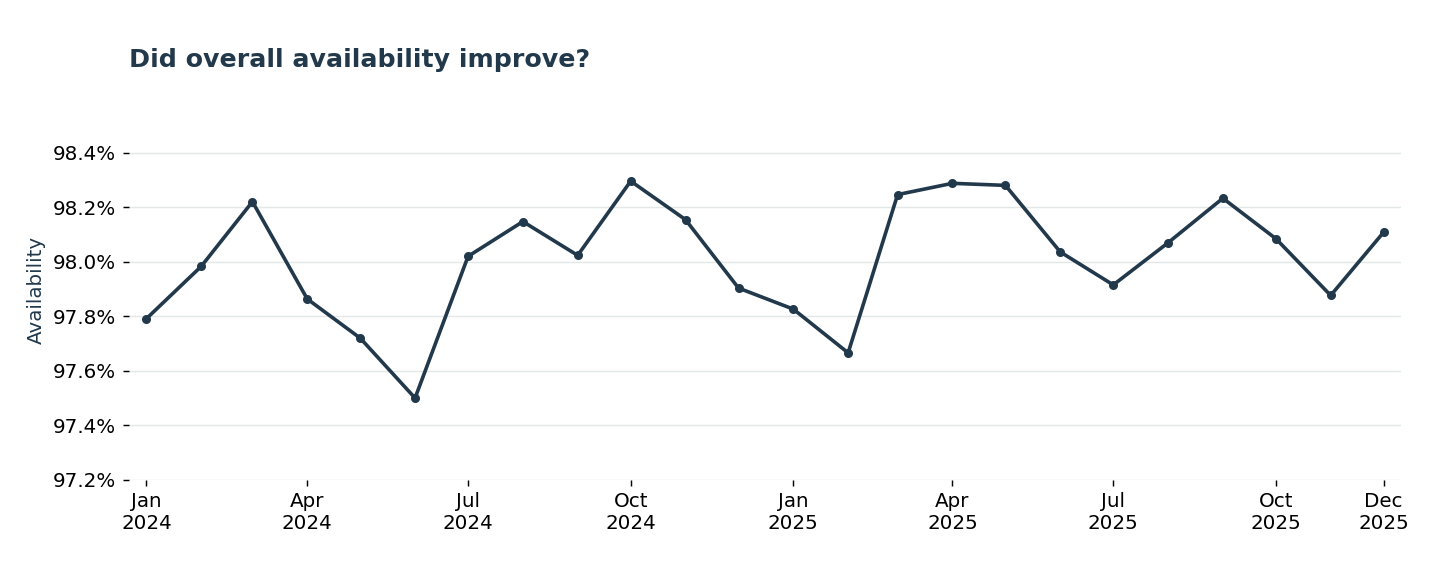

In [5]:
monthly = data.groupby("Month")[["24-Hour Hours Available", "24-Hour Total Hours"]].sum()
monthly["availability"] = monthly["24-Hour Hours Available"] / monthly["24-Hour Total Hours"]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["availability"], color=NAVY, marker="o", markersize=4, linewidth=2)
ax.set_title("Did overall availability improve?", loc="left", pad=18)
ax.set_ylabel("Availability")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_ylim(monthly["availability"].min() - .003, monthly["availability"].max() + .003)
ax.set_xticks(monthly.index[::3].tolist() + [monthly.index[-1]])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax.set_xlim(monthly.index.min() - pd.Timedelta(days=10),
            monthly.index.max() + pd.Timedelta(days=10))
ax.grid(axis="y", color="#E4E7E8", linewidth=.8)
fig.subplots_adjust(left=.09, right=.98, bottom=.18, top=.83)
save_chart(fig, "01_monthly_availability.png")


## 5. How different was availability between elevators?

The three groups describe 2025 annual availability across all 211 elevators.
A small number of groups makes the distribution readable without 211 separate bars.
The bands are descriptive choices, not MTA performance targets.

The six elevators below 95% are not automatically the same cases as the 18 with
lower year-to-year availability. A level and a change answer different questions.


Below 95%             6
95% to under 98%     63
98% or higher       142


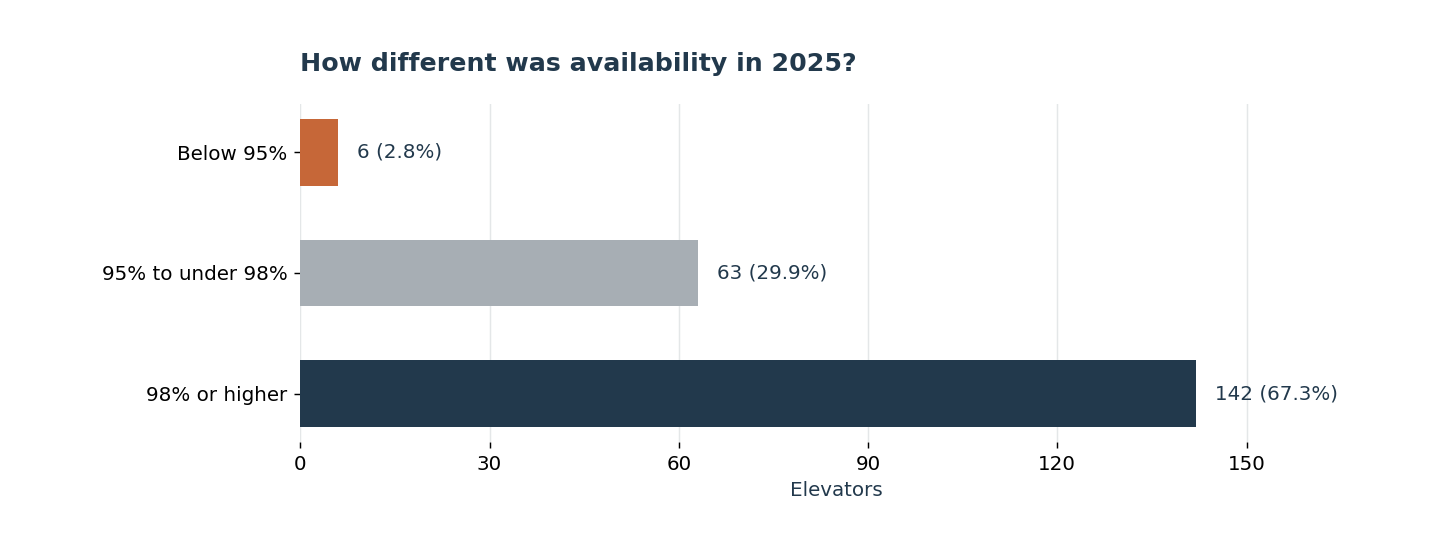

In [6]:
rates_2025 = rates[2025]
band_counts = pd.Series({
    "Below 95%": int((rates_2025 < .95).sum()),
    "95% to under 98%": int(((rates_2025 >= .95) & (rates_2025 < .98)).sum()),
    "98% or higher": int((rates_2025 >= .98).sum()),
})
print(band_counts.to_string())

fig, ax = plt.subplots(figsize=(11, 4.2))
bars = ax.barh(band_counts.index, band_counts.values, color=[ORANGE, GRAY, NAVY], height=.55)
ax.invert_yaxis()
ax.set_xlim(0, 170)
ax.set_xlabel("Elevators")
ax.set_title("How different was availability in 2025?", loc="left", pad=18)
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
ax.grid(axis="x", color="#E4E7E8", linewidth=.8)
for bar, value in zip(bars, band_counts.values):
    ax.text(value + 3, bar.get_y() + bar.get_height() / 2,
            f"{value} ({100 * value / len(rates_2025):.1f}%)", va="center")
fig.subplots_adjust(left=.21, right=.96, bottom=.19, top=.81)
save_chart(fig, "02_availability_groups.png")


## 6. Of the 102 with fewer outages, how many improved availability?

Most did: 84 improved availability. But 18 went in the opposite direction.
The share is 18 divided by 102, or 17.6%, rather than 18 divided by all 211.

I used a simple breakdown here so the outcome and denominator are immediate.
It establishes why the following views examine the 18 exceptions.


Fewer outages: 102
Improved availability: 84
Lower availability: 18
Share with lower availability: 17.6%


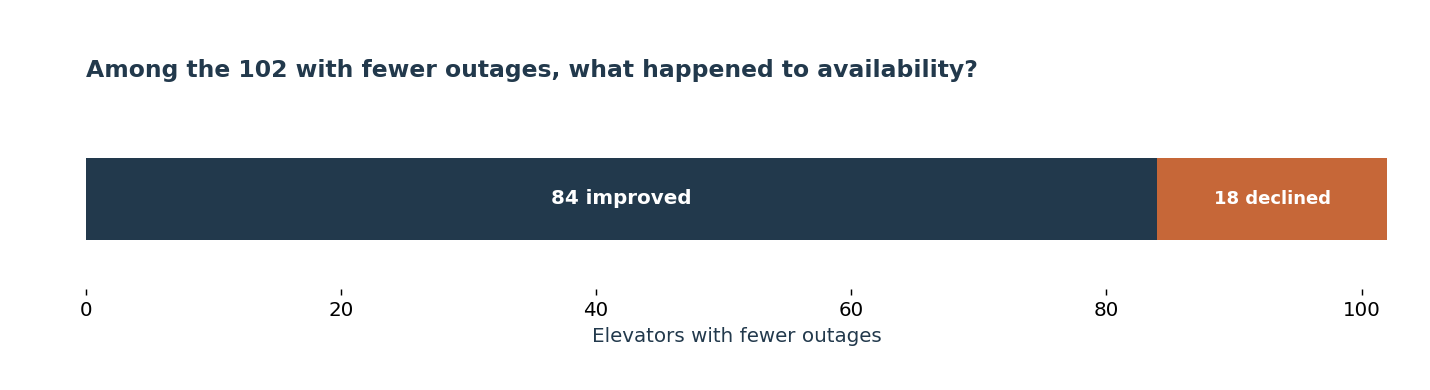

In [7]:
outcome_counts = [int(improved.sum()), int(exceptions.sum())]
print("Fewer outages:", int(fewer.sum()))
print("Improved availability:", outcome_counts[0])
print("Lower availability:", outcome_counts[1])
print(f"Share with lower availability: {100 * outcome_counts[1] / fewer.sum():.1f}%")

fig, ax = plt.subplots(figsize=(11, 3))
ax.barh(0, outcome_counts[0], color=NAVY, height=.55)
ax.barh(0, outcome_counts[1], left=outcome_counts[0], color=ORANGE, height=.55)
ax.text(outcome_counts[0] / 2, 0, f"{outcome_counts[0]} improved", color="white",
        ha="center", va="center", fontweight="bold")
ax.text(outcome_counts[0] + outcome_counts[1] / 2, 0, f"{outcome_counts[1]} declined",
        color="white", ha="center", va="center", fontweight="bold", fontsize=10)
ax.set_xlim(0, int(fewer.sum()))
ax.set_ylim(-.6, .6)
ax.set_yticks([])
ax.set_xlabel("Elevators with fewer outages")
ax.set_title("Among the 102 with fewer outages, what happened to availability?",
             loc="left", pad=18, fontsize=13)
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
fig.subplots_adjust(left=.06, right=.97, bottom=.26, top=.72)
save_chart(fig, "03_availability_outcomes.png")


## 7. Which of those 18 lost the most availability?

Paired dots compare each elevator's 2024 and 2025 annual rates on one scale.
Sorting by the change puts the largest declines first. This avoids treating all
18 as equally substantial.

Some endpoints almost overlap. EL506's rate fell by roughly 0.0006 percentage point
even though actual downtime decreased slightly: 2024 had 366 days and 2025 had 365.
Seventeen of the 18 had more raw downtime.


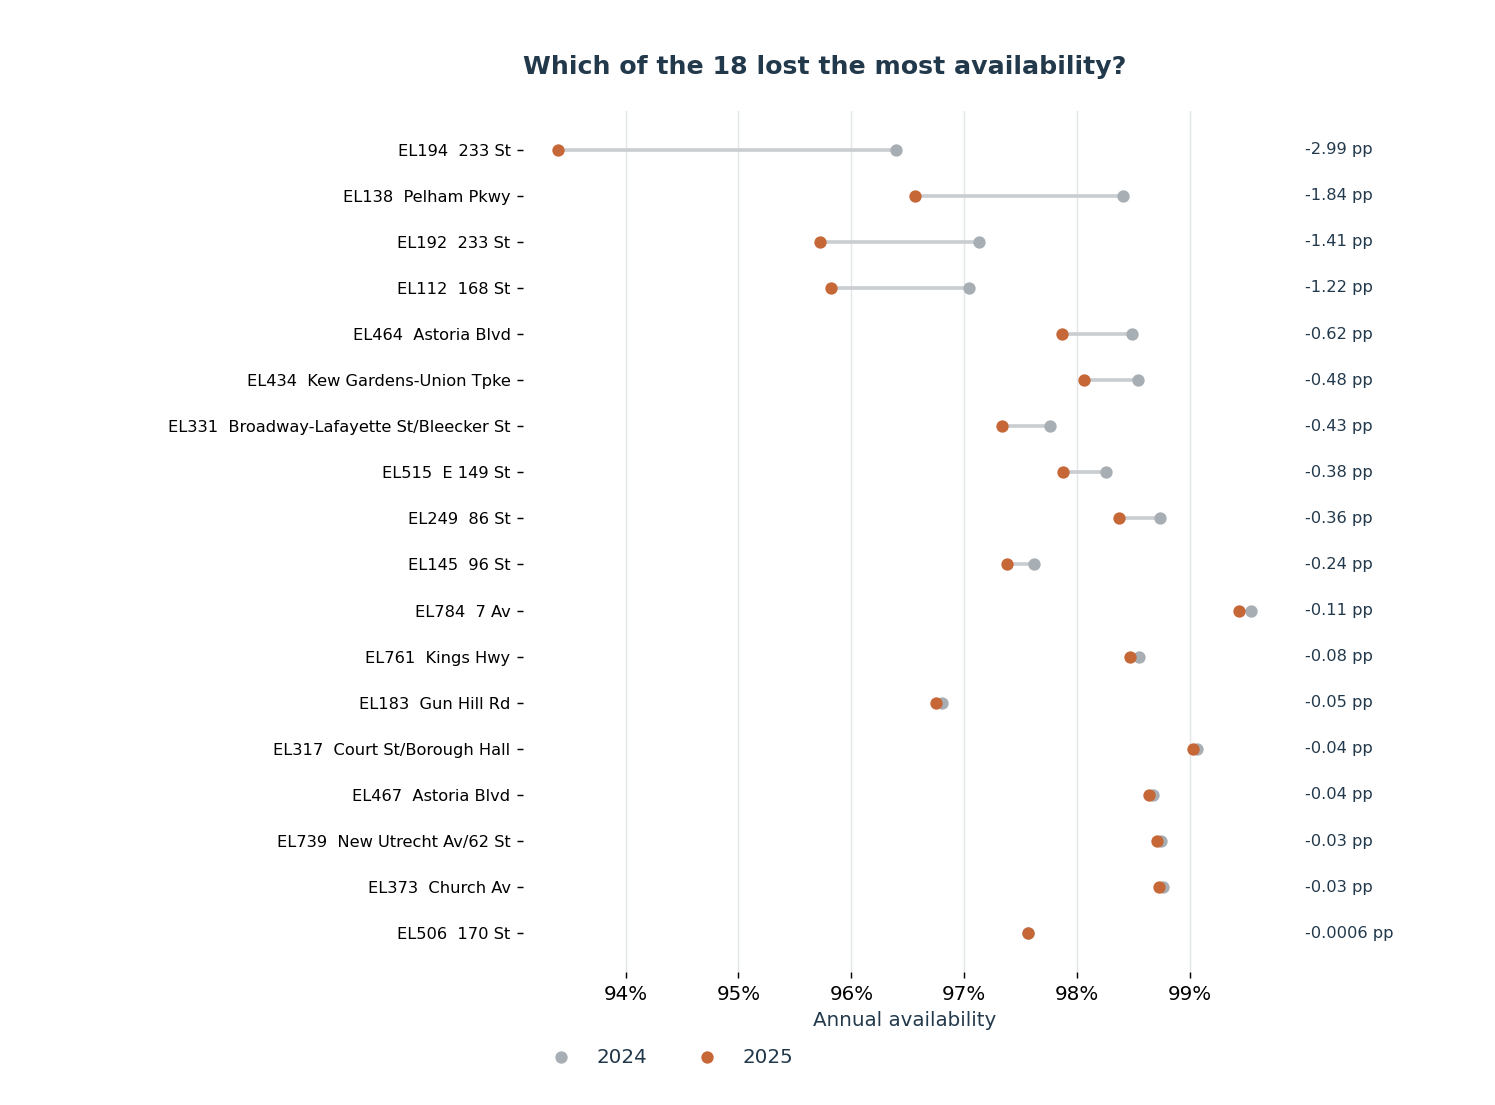

In [8]:
row_labels = [f"{equipment}  {station_names.loc[equipment]}" for equipment in exception_order]
y = np.arange(len(exception_order))
values_2024 = rates.loc[exception_order, 2024].to_numpy() * 100
values_2025 = rates.loc[exception_order, 2025].to_numpy() * 100

fig, ax = plt.subplots(figsize=(11.5, 8.5))
ax.hlines(y, values_2025, values_2024, color="#C9CDD0", linewidth=2, zorder=1)
ax.scatter(values_2024, y, color=GRAY, s=34, label="2024", zorder=2)
ax.scatter(values_2025, y, color=ORANGE, s=34, label="2025", zorder=3)
ax.set_yticks(y, labels=row_labels, fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_xlabel("Annual availability")
ax.set_title("Which of the 18 lost the most availability?", loc="left", pad=20)
ax.grid(axis="x", color="#E4E7E8", linewidth=.8)
for position, equipment in enumerate(exception_order):
    change = comparison.loc[equipment, "availability_change_pp"]
    label = f"{change:.2f} pp" if abs(change) >= .01 else f"{change:.4f} pp"
    ax.text(1.025, position, label, transform=ax.get_yaxis_transform(), va="center", fontsize=9)
ax.legend(loc="lower left", bbox_to_anchor=(0, -.13), ncol=2, frameon=False)
fig.subplots_adjust(left=.35, right=.86, top=.90, bottom=.12)
save_chart(fig, "04_annual_comparison.png")


## 8. When were those elevators least available?

The heatmap follows the same 18, in the same order as the annual comparison.
Each row has 12 monthly cells for 2025. Darker cells indicate lower availability.
This shows whether a low annual rate was concentrated in a few months or spread out.

The heatmap uses the exception group, not the legacy top-ten-downtime field retained
in the export. There are 18 times 12, or 216 cells.


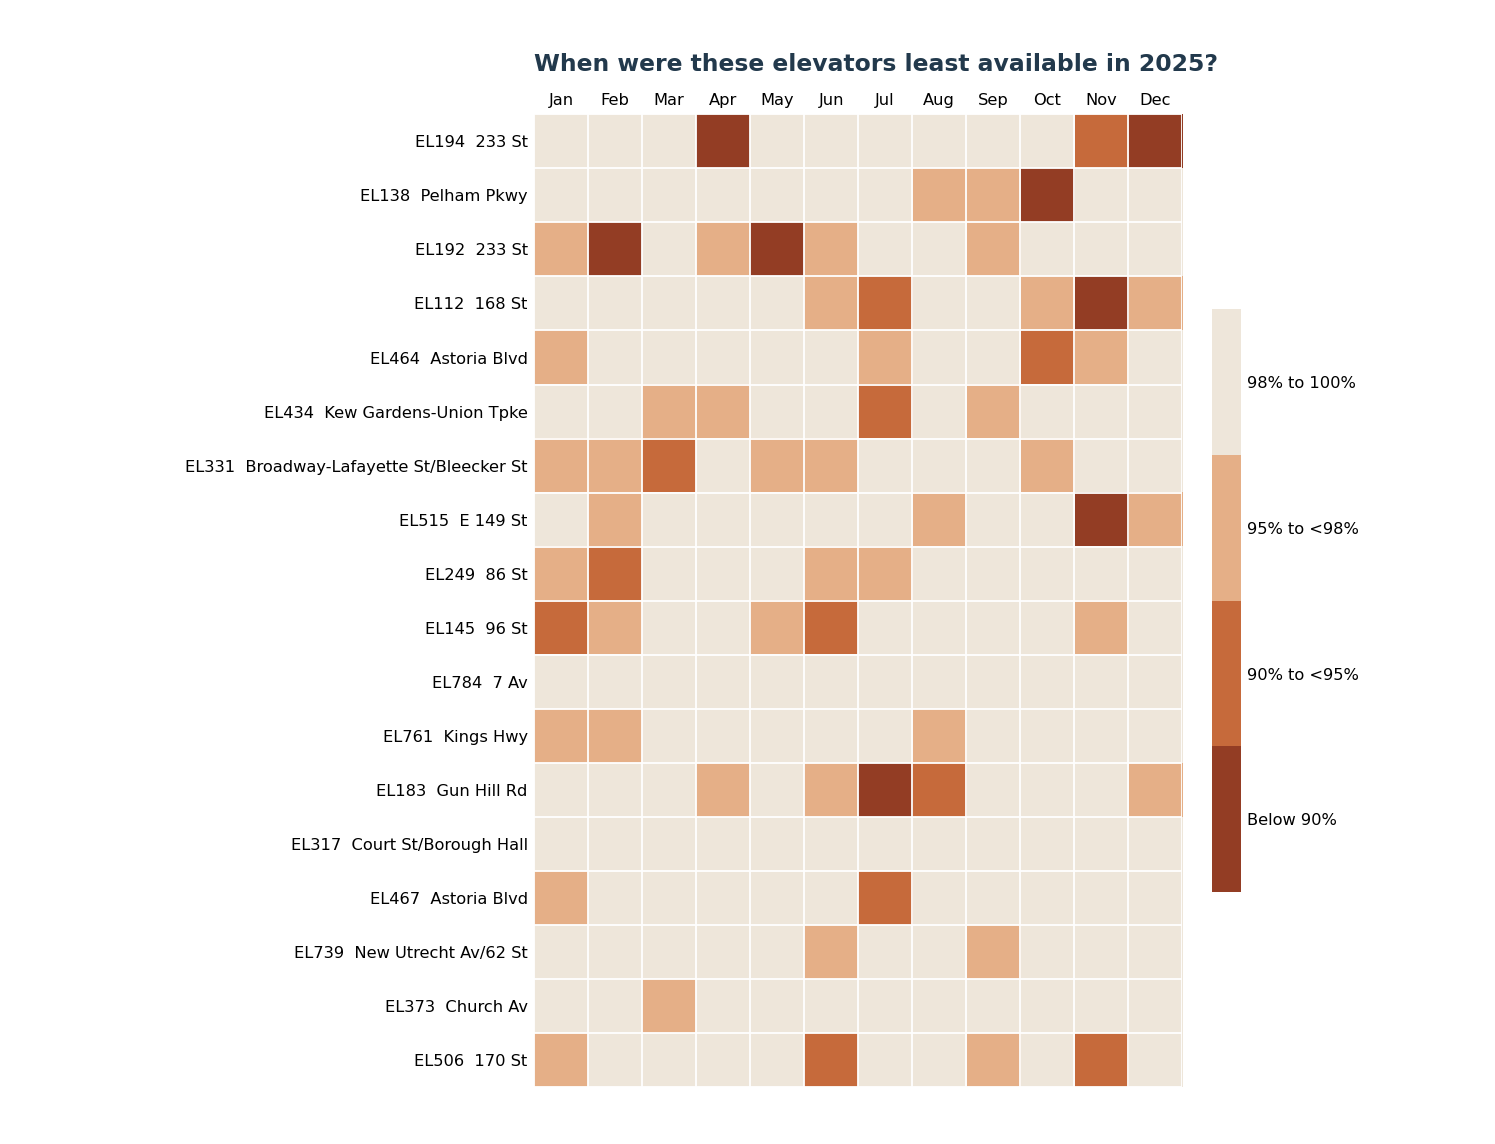

In [9]:
focused = data.loc[data["Year"].eq(2025) & data["Equipment Code"].isin(exception_order)].copy()
focused["month_number"] = focused["Month"].dt.month
heatmap = focused.pivot(index="Equipment Code", columns="month_number", values="Monthly Availability")
heatmap = heatmap.reindex(index=exception_order, columns=range(1, 13))
assert heatmap.shape == (18, 12) and not heatmap.isna().any().any()
bands = np.select([heatmap < .90, heatmap < .95, heatmap < .98], [0, 1, 2], default=3)

fig, ax = plt.subplots(figsize=(11.5, 8.8))
image = ax.imshow(bands, cmap=ListedColormap(["#933D24", "#C66A3B", "#E5AF87", "#EEE6DA"]),
                  vmin=-.5, vmax=3.5, aspect="equal")
ax.set_yticks(y, labels=row_labels, fontsize=9)
ax.set_xticks(range(12), labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], fontsize=9)
ax.xaxis.tick_top()
ax.set_title("When were these elevators least available in 2025?", loc="left", pad=24, fontsize=13)
ax.set_xticks(np.arange(-.5, 12, 1), minor=True)
ax.set_yticks(np.arange(-.5, 18, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="both", length=0)
colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1, 2, 3], fraction=.04, pad=.04, shrink=.6)
colorbar.ax.set_yticklabels(["Below 90%", "90% to <95%", "95% to <98%", "98% to 100%"])
colorbar.ax.tick_params(labelsize=9, length=0)
colorbar.outline.set_visible(False)
fig.subplots_adjust(left=.34, right=.83, top=.90, bottom=.05)
save_chart(fig, "05_monthly_patterns.png")


## 9. What deserves a closer look?

Across the selected 18, recorded outages fell from 775 to 665, while downtime rose
from about 2,983 to 3,882 hours. EL194 and EL138 account for about 47% of the group's
net additional downtime.

At 233 St, EL194 recorded 67 outages in 2024 and 43 in 2025, while downtime increased
from about 317 to 578 hours. April and December account for about 76% of its 2025
downtime. Those months would be useful places to start an incident-level investigation.

The group was selected for fewer outages and lower availability. These figures
describe the size of that pattern; they do not show that fewer outages caused more
downtime. Monthly totals cannot establish whether long repairs, outage mix or other
factors explain the results.


In [10]:
group_outages = outages.loc[exception_order].sum()
group_downtime = downtime.loc[exception_order].sum()
net_increase = group_downtime[2025] - group_downtime[2024]
two_increase = comparison.loc[["EL194", "EL138"], "downtime_change_hours"].sum()

print("Selected 18 outages:", group_outages.to_dict())
print("Selected 18 downtime hours:", group_downtime.round(1).to_dict())
print(f"Net additional downtime: {net_increase:.1f} hours")
print(f"EL194 and EL138 contribution: {two_increase:.1f} hours ({100 * two_increase / net_increase:.1f}%)")
print("\nEL194 annual results:")
print(annual.loc["EL194", ["outages", "downtime"]].to_string(float_format=lambda value: f"{value:.1f}"))
el194 = focused.loc[focused["Equipment Code"].eq("EL194")].set_index("month_number")
concentrated_share = el194.loc[[4, 12], "Downtime Hours"].sum() / el194["Downtime Hours"].sum()
print(f"\nApril and December share of EL194's 2025 downtime: {100 * concentrated_share:.1f}%")


Selected 18 outages: {2024: 775, 2025: 665}
Selected 18 downtime hours: {2024: 2982.9, 2025: 3881.5}
Net additional downtime: 898.6 hours
EL194 and EL138 contribution: 422.2 hours (47.0%)

EL194 annual results:
      outages  downtime
Year                   
2024       67     317.0
2025       43     578.1

April and December share of EL194's 2025 downtime: 75.9%


## 10. Summarize the findings

This overview combines the 84/18 outcome with the 2025 distribution. The two panels
use different denominators: 102 elevators with fewer outages on the left, and all
211 comparison elevators on the right.


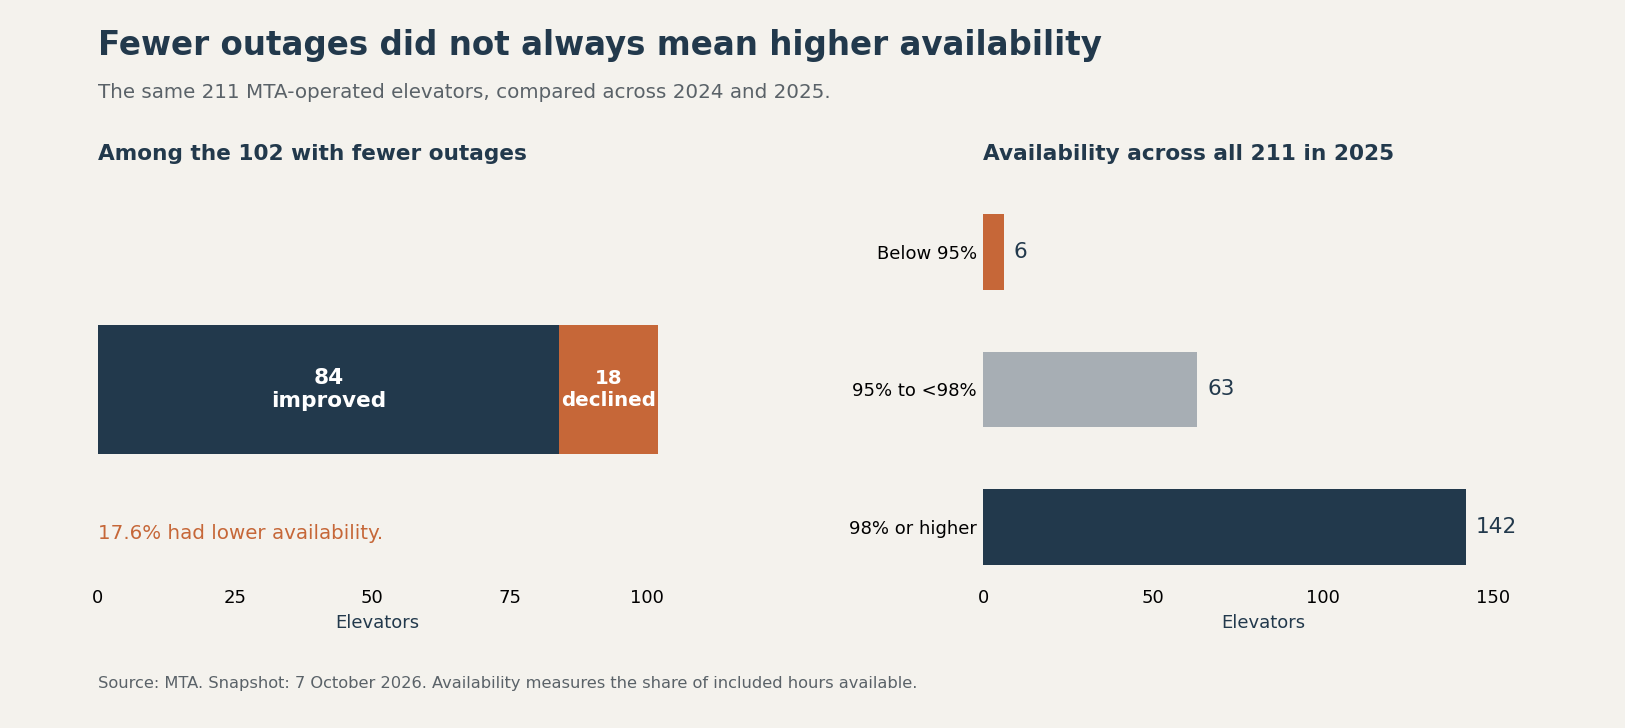

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6), facecolor="#F4F2ED")
fig.suptitle("Fewer outages did not always mean higher availability",
             x=.06, y=.96, ha="left", fontsize=18, fontweight="bold", color=NAVY)
fig.text(.06, .865, "The same 211 MTA-operated elevators, compared across 2024 and 2025.",
         fontsize=11, color="#5A6268")

left, right = axes
left.set_title("Among the 102 with fewer outages", loc="left", fontsize=12, pad=20)
improved_count, declined_count = outcome_counts
left.barh(0, improved_count, color=NAVY, height=.5)
left.barh(0, declined_count, left=improved_count, color=ORANGE, height=.5)
left.text(improved_count / 2, 0, f"{improved_count}\nimproved",
          ha="center", va="center", color="white", fontweight="bold", fontsize=12)
left.text(improved_count + declined_count / 2, 0, f"{declined_count}\ndeclined",
          ha="center", va="center", color="white", fontweight="bold", fontsize=11)
left.set_xlim(0, int(fewer.sum()))
left.set_ylim(-.75, .75)
left.set_yticks([])
left.set_xticks([0, 25, 50, 75, 100])
left.set_xlabel("Elevators", fontsize=10)
left.text(0, -.58, f"{100 * declined_count / fewer.sum():.1f}% had lower availability.",
          fontsize=11, color=ORANGE)

right.set_title("Availability across all 211 in 2025", loc="left", fontsize=12, pad=20)
overview_labels = ["Below 95%", "95% to <98%", "98% or higher"]
bars = right.barh(overview_labels, band_counts.values, color=[ORANGE, GRAY, NAVY], height=.55)
right.invert_yaxis()
right.set_xlim(0, 165)
right.set_xticks([0, 50, 100, 150])
right.set_xlabel("Elevators", fontsize=10)
for bar, value in zip(bars, band_counts.values):
    right.text(value + 3, bar.get_y() + bar.get_height()/2, str(value), va="center", fontsize=12)
for axis in axes:
    axis.set_facecolor("#F4F2ED")
    axis.tick_params(axis="both", labelsize=10, length=0)
fig.text(.06, .055, "Source: MTA. Snapshot: 7 October 2026. Availability measures the share of included hours available.",
         fontsize=9, color="#5A6268")
fig.subplots_adjust(left=.06, right=.95, top=.73, bottom=.20, wspace=.58)
save_chart(fig, "overview.png")


## 11. Validate the exported data

Matching the headline counts alone would not be enough. I compare the complete export
against the CSV embedded in the Tableau workbook and check its SHA-256 fingerprint.
The validation also checks source quality, field order, equipment-month keys, exact
counts and flags, numerical values and the main results.


In [12]:
validation = verify(RAW, PREPARED, REFERENCE)
(ROOT / "reports/validation.json").write_text(
    json.dumps(validation, indent=2) + "\n", encoding="utf-8"
)
print("Validation:", validation["status"])
print("Prepared CSV SHA-256:", validation["comparison"]["generated_sha256"])
print("Full schema and equipment-month keys match:", validation["comparison"]["key_sets_identical"])
print("All numeric fields match:", validation["comparison"]["numeric_values_match"])


Validation: byte-identical
Prepared CSV SHA-256: 194e7d92d041f76459b31a7ecb0b22c54c0713fa7c7a8047e1e3d1261cab8272
Full schema and equipment-month keys match: True
All numeric fields match: True


## Conclusion and limitations

Outage counts and time unavailable should be read together. Fewer interruptions
did not always mean better availability for the elevators in this comparison.
The larger contributors within the 18 provide specific cases to investigate, rather
than a network-wide maintenance ranking.

I would need incident start/end times, outage categories and repair records to test
possible explanations. These monthly summaries cannot measure individual repair
durations, passenger impacts or whether an entire accessible route was available.
Scheduled interruptions are included in total outages, so a lower count is not
necessarily fewer breakdowns. Entrapments are already included in unscheduled counts.

The full-calendar cohort excludes equipment with incomplete or excluded observation
hours. The findings describe that group. Some availability changes are tiny, and
the heatmap bands are descriptive choices rather than MTA targets.
